In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from datasets import load_dataset

In [2]:
emotion_dataset = load_dataset("dair-ai/emotion")

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
emotion_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [4]:
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']
test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

df_train = pd.DataFrame({
    'text' : train_text,
    'label' : train_label
})

df_test = pd.DataFrame({
    'text' : test_text,
    'label' : test_label
})

data_labels = emotion_dataset['train'].features['label'].names

df_train['label'] = [data_labels[i] for i in df_train['label']]
df_test['label'] = [data_labels[i] for i in df_test['label']]
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [5]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [6]:
df_train.isnull().sum()

,0
text,0
label,0


<Axes: xlabel='label', ylabel='count'>

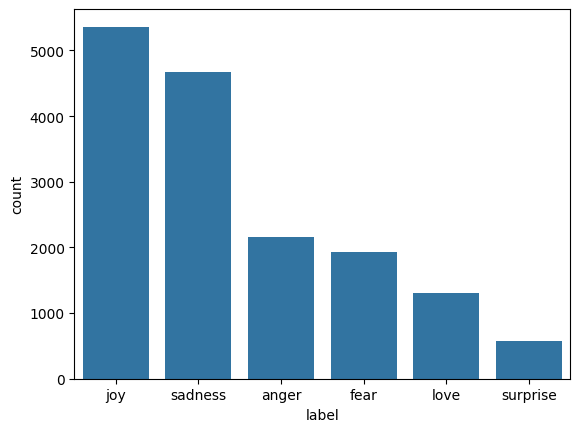

In [7]:
order = df_train['label'].value_counts().index.tolist()
sns.countplot(x='label',data=df_train,order=order)


In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

voc_size  = 10000
toknizer = Tokenizer(num_words=voc_size, oov_token='<oov>')
toknizer.fit_on_texts(df_train['text'])

train_seq = toknizer.texts_to_sequences(df_train['text'])
test_seq = toknizer.texts_to_sequences(df_test['text'])

max_len = max([len(i) for i in train_seq])

pad_train_seq = pad_sequences(train_seq,maxlen = max_len,padding='post')
pad_test_seq = pad_sequences(test_seq,maxlen = max_len,padding='post')

train_labels = np.array(train_label)
test_labels  = np.array(test_label)

num_classes = len(np.unique(train_labels))


In [9]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dic = dict(enumerate(class_weights))
class_weight_dic

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,Bidirectional,GRU,Dense,Dropout

model = Sequential([
    Embedding(input_dim = voc_size,output_dim =300,input_length=max_len),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(32)),
    Dropout(0.5),
    Dense(num_classes,activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.fit(
    pad_train_seq,
    train_labels,
    validation_data=(pad_test_seq,test_labels),
    batch_size=100,
    epochs=10,
    class_weight=class_weight_dic,
    callbacks=[es]
)

Epoch 1/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.3169 - loss: 1.5501 - val_accuracy: 0.5120 - val_loss: 1.0628
Epoch 2/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8324 - loss: 0.4993 - val_accuracy: 0.8795 - val_loss: 0.3916
Epoch 3/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9231 - loss: 0.2560 - val_accuracy: 0.9015 - val_loss: 0.3301
Epoch 4/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9421 - loss: 0.1860 - val_accuracy: 0.9105 - val_loss: 0.3346
Epoch 5/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9588 - loss: 0.1350 - val_accuracy: 0.9135 - val_loss: 0.2981
Epoch 6/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9669 - loss: 0.1075 - val_accuracy: 0.8930 - val_loss: 0.4051
Epoch 7/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9722 - loss: 0.0912 - val_accuracy: 0.9165 - val_loss: 0.3262
Epoch 8/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9759 - loss: 0.0786 - val_acc

In [13]:
testing_loss,testing_auc = model.evaluate(pad_test_seq,test_labels)

print(f'Testing Loss : {testing_loss}')
print(f'Testing AUC : {testing_auc}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9135 - loss: 0.2981
Testing Loss : 0.2980949580669403
Testing AUC : 0.9135000109672546


In [14]:
sample_text = [
    "i am very happy today",
    "i am very sad today",
    "i am very angry today",
    "i am very excited today",
    "i am very disappointed today"
]

sample_seq = toknizer.texts_to_sequences(sample_text)
sample_pad = pad_sequences(sample_seq,maxlen=max_len,padding='post')

pred = model.predict(sample_pad)
pred_labels = np.argmax(pred,axis=1)

for i in range(len(sample_text)):
  print(f"Text : {sample_text[i]}")
  print(f"prediction label : {data_labels[pred_labels[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 643ms/step
Text : i am very happy today
prediction label : joy
Text : i am very sad today
prediction label : sadness
Text : i am very angry today
prediction label : anger
Text : i am very excited today
prediction label : joy
Text : i am very disappointed today
prediction label : sadness


In [15]:
import os
import pickle

model_dir = "Artifacts"
os.makedirs(model_dir,exist_ok=True)
model.save(os.path.join(model_dir,"Bidirectional_GRU_model.keras"))
with open(os.path.join(model_dir,"tokenizer.pkl"), "wb") as f:
  pickle.dump(toknizer,f)
